# Task 1 (extra) - Undersampling with ENN (Edited Nearest Neighbours)
Extra part of Task 1. The main work (RandomUnderSampler) is in `01_undersampling`.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

df = pd.read_csv("../../../Datasets/adult.csv")  

# drop the duplicates and replace the "?" with NaN, then drop the NaN values
df = df.drop_duplicates()
df = df.replace("?", np.nan).dropna()

# numeric columns only, and reset the index
df = df[["age", "education.num", "hours.per.week", "income"]].reset_index(drop=True)   

# Binary encoding the 'income' column
df["income"] = df["income"].replace({"<=50K": 0, ">50K": 1})
df["income"] = df["income"].astype(int)

df

,age,education.num,hours.per.week,income
0,82,9,18,0
1,54,4,40,0
2,41,10,40,0
3,34,9,45,0
4,38,6,40,0
...,...,...,...,...
30134,22,10,40,0
30135,27,12,38,0
30136,40,9,40,1
30137,58,9,40,0


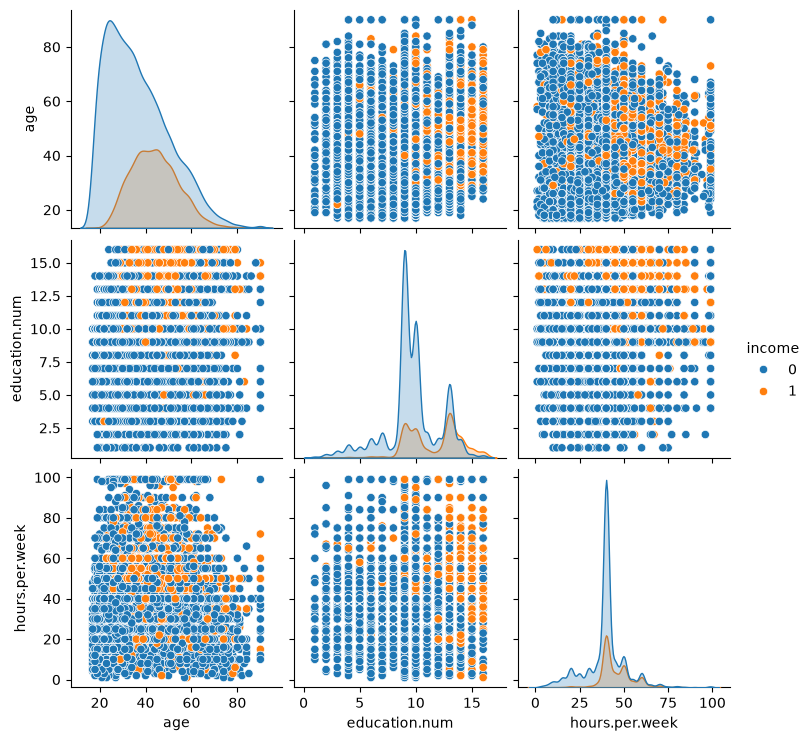

In [ ]:
# we can see that there is a huge overlap between the two classes, and the dataset is imbalanced. 
# Let's visualize this using a pairplot.
sns.pairplot(df, hue="income")

In [6]:
df.shape

(30139, 4)

In [7]:
from imblearn.under_sampling import EditedNearestNeighbours

# X y split
X = df.drop("income", axis=1)
y = df["income"]

# Initializing ENN
enn = EditedNearestNeighbours(
    n_neighbors=4,
    kind_sel="all"
)

# Resample using ENN
X_clean, y_clean = enn.fit_resample(X, y)

# Make a new dataframe and add y_clean back into it.
df_undersampled = pd.DataFrame(X_clean)
df_undersampled["income"] = y_clean

In [8]:
df_undersampled.shape

(18019, 4)

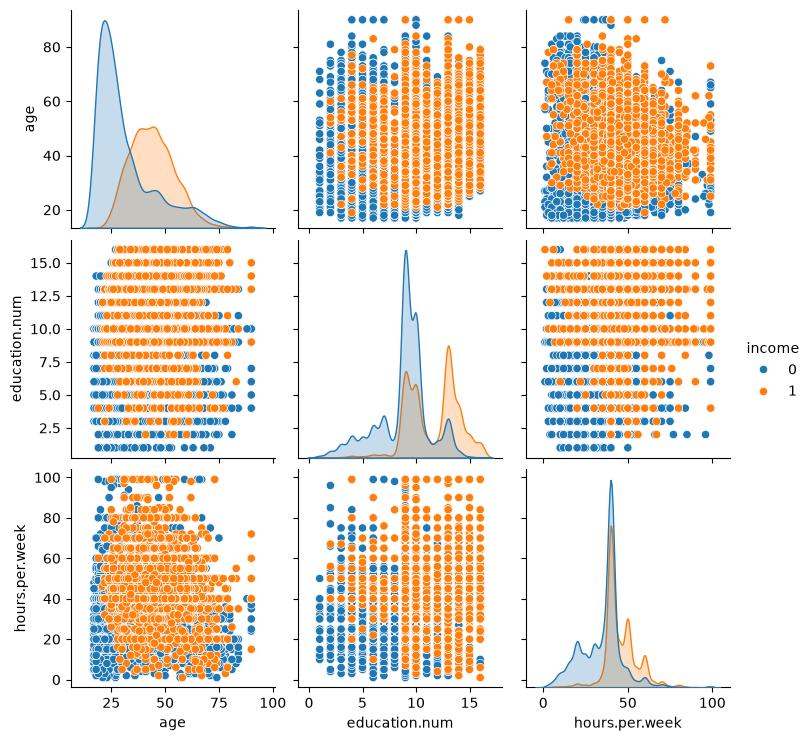

In [ ]:

sns.pairplot(df_undersampled, hue="income")

### Conclusion

- Rows Before: 30139, After: 18019 (12,120 removed)
- In the pairplot after ENN there is quite less overlap between the income classes than before, but some overlap still remains.
- It cleans the boundry between the classes instead of forcing an even split and therefore it did not balance the data fully but it improved the balanced a little.
- ENN is an aggressive metod, so the data may no longer reflects the reality because a lot of real data was lost.
- It works best when the classes overlap or there is noise at the boundary and the dataset is large enough to lose some rows.